# Open-loop controller training

Implements `rl_methods/OPEN_LOOP.md`. The LLM stays frozen: this notebook only reads recorded traces.

- **Input:** the question (PCA-64 + 2 scalars) and the controller's **own past actions** (9 scalars).
  It never sees an answer or a token count.
- **Output:** one action at a time: RUN, ADD, ESC or STOP. There are 55 legal sequences.
- **Method:** PPO. One model per λ, 5 seeds.
- **Selection:** exact validation utility. The test split is not loaded until `RUN_TEST = True`.

Run all cells from top to bottom. Outputs go to `rl_training/outputs/open_loop/`.

## 1. Settings

In [1]:
import itertools, json, math, os, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
DATA = ROOT / "controller_data"
EMB = DATA / "embeddings"
OUT = Path(os.environ.get("OPEN_OUT", ROOT / "rl_training" / "outputs" / "open_loop"))
BANDIT_DIR = Path(os.environ.get("BANDIT_DIR", ROOT / "rl_training" / "outputs" / "bandit"))
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "cache").mkdir(exist_ok=True)
FIGURES = OUT / "figures" if "OPEN_OUT" in os.environ else ROOT / "figures" / "open_loop"
FIGURES.mkdir(parents=True, exist_ok=True)

RUN_TEST = False            # set True ONCE, after every choice has been made on validation
SMOKE = os.environ.get("OPEN_SMOKE") == "1"   # short run used to check the code

EMB_DIM = 64
SEEDS = [0] if SMOKE else [0, 1, 2, 3, 4]
LAMBDAS = [0.02, 0.05, 0.10, 0.25, 0.50]
N_ENVS = 64                 # parallel replay episodes
TOTAL_STEPS = 12_800 if SMOKE else 1_000_000
EVAL_EVERY = 6_400 if SMOKE else 50_000
N_BOOT = 200 if SMOKE else 10_000

PPO = dict(lr=3e-4, rollout=2_048, epochs=4, minibatch=256, clip=0.2, gae=0.95, value=0.5, ent_start=0.01, ent_end=0.001,
           grad_clip=0.5, aux=0.1)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONFIG = "t0.6_pp1.5"
DATASETS = ["gsm8k", "math", "amc23"]
LEVELS = {
    "gsm8k": dict(L=2048, M=4096, H=16384),
    "math": dict(L=4096, M=12288, H=16384),
    "amc23": dict(L=12288, M=24576, H=32768),
}
LEVEL_NAMES = ["L", "M", "H"]
ACTIONS = ["RUN_L", "RUN_M", "RUN_H", "STOP", "ADD", "ESC_M", "ESC_H"]
A = {name: i for i, name in enumerate(ACTIONS)}
print("device", DEVICE, "| smoke", SMOKE, "| test", RUN_TEST)

device cuda | smoke False | test False


## How seeds work

A **seed** is a starting number for a random-number generator. The same seed gives the same random choices, so a run can be repeated.

| Seed | Value | How it is made | What it controls |
|---|---|---|---|
| Data split | `2026` | fixed in `prepare_data.py` / `prepare_math.py` | which questions go to train, validation, test |
| LLM recording | one per trace | SHA-256 of `question_id\|sample`, first 8 hex digits as a number | the random sampling of that recorded answer |
| **Training** | `0, 1, 2, 3, 4` | written in `SEEDS` | starting weights, sampled questions, traces and actions |
| Bootstrap | `0` | fixed | the question resampling used for the 95% ranges |

Training the same model with 5 seeds shows how much a result depends on luck.

In [2]:
import hashlib

def recording_seed(question_id, sample):
    return int(hashlib.sha256(f"{question_id}|{sample}".encode()).hexdigest()[:8], 16)

print("Recording seeds of question 'gsm8k-1':", [recording_seed("gsm8k-1", k) for k in range(3)])
torch.manual_seed(0); first = torch.rand(3).tolist()
torch.manual_seed(0); again = torch.rand(3).tolist()
torch.manual_seed(1); other = torch.rand(3).tolist()
print("seed 0:", [round(x, 3) for x in first], "| seed 0 again:", [round(x, 3) for x in again], "| seed 1:", [round(x, 3) for x in other])

Recording seeds of question 'gsm8k-1': [1973596014, 3079404675, 3808998835]
seed 0: [0.496, 0.768, 0.088] | seed 0 again: [0.496, 0.768, 0.088] | seed 1: [0.758, 0.279, 0.403]


## 2. Load the recordings

Each question becomes arrays of shape `(3 levels, 10 traces)`: tokens, correct, answer cluster.
Clusters never use the reference.

In [3]:
sys.path.insert(0, str(ROOT / "generation_math" / "src"))
from grade_math import answer_box, parse, verify  # noqa: E402


def mv_equal(a, b):
    try:
        return bool(a and b and (verify(a, b) or verify(b, a)))
    except Exception:
        return False


def cluster_math(preds, boxes):
    """Cluster ids for one question's answers. Invalid answers (None) get -1."""
    unique = sorted({p for p in preds if p is not None})
    parent = list(range(len(unique)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    first_box = {}
    for p, b in zip(preds, boxes):
        if p is not None and p not in first_box:
            first_box[p] = b
    parsed = []
    for u in unique:
        try:
            parsed.append(parse("\\boxed{" + first_box[u] + "}"))
        except Exception:
            parsed.append(None)
    for i, j in itertools.combinations(range(len(unique)), 2):
        if find(i) != find(j) and mv_equal(parsed[i], parsed[j]):
            parent[find(j)] = find(i)
    roots = {r: n for n, r in enumerate(sorted({find(i) for i in range(len(unique))}))}
    ids = {u: roots[find(i)] for i, u in enumerate(unique)}
    return np.array([ids[p] if p is not None else -1 for p in preds], dtype=np.int16)


def load_set(dataset, split):
    cache = OUT / "cache" / f"{dataset}_{split}.npz"
    q_ids = [str(x) for x in np.load(EMB / f"{dataset}_{split}_q_ids.npy", allow_pickle=True)]
    if cache.exists():
        z = np.load(cache)
        arrays = {k: z[k] for k in z.files}
    else:
        cols = ["question_id", "sample", "budget", "config", "pred", "valid", "correct", "total_tokens",
                "prompt_tokens", "n_numbers"] + ([] if dataset == "gsm8k" else ["answer_text"])
        df = pd.read_csv(DATA / f"{dataset}_{split}_controller.csv", usecols=cols, na_filter=False,
                         dtype={"question_id": str, "pred": str})
        budgets = [LEVELS[dataset][l] for l in LEVEL_NAMES]
        df = df[(df.config == CONFIG) & df.budget.isin(budgets)]
        assert len(df) == len(q_ids) * 3 * 10, (dataset, split, len(df))
        q_pos, lev_pos = {q: i for i, q in enumerate(q_ids)}, {b: i for i, b in enumerate(budgets)}
        samples = {s: i for i, s in enumerate(sorted(df["sample"].unique()))}
        assert len(samples) == 10
        q = df.question_id.map(q_pos).to_numpy()
        l = df.budget.map(lev_pos).to_numpy()
        s = df["sample"].map(samples).to_numpy()
        shape = (len(q_ids), 3, 10)
        tok, cor, cid = np.zeros(shape, np.float32), np.zeros(shape, np.float32), -np.ones(shape, np.int16)
        tok[q, l, s] = df.total_tokens.to_numpy()
        valid = df.valid.to_numpy().astype(bool)
        cor[q, l, s] = df.correct.to_numpy() * valid
        pred_grid = np.empty(shape, dtype=object)
        pred_grid[q, l, s] = [p if v else None for p, v in zip(df.pred, valid)]
        if dataset == "gsm8k":
            for i in range(len(q_ids)):
                values = [None if p is None else float(p) for p in pred_grid[i].ravel()]
                unique = {v: n for n, v in enumerate(sorted({v for v in values if v is not None}))}
                cid[i] = np.array([-1 if v is None else unique[v] for v in values]).reshape(3, 10)
        else:
            box_grid = np.empty(shape, dtype=object)
            box_grid[q, l, s] = [answer_box(t) if v else None for t, v in zip(df.answer_text, valid)]
            for i in range(len(q_ids)):
                cid[i] = cluster_math(list(pred_grid[i].ravel()), list(box_grid[i].ravel())).reshape(3, 10)
        first = df.drop_duplicates("question_id").set_index("question_id")
        arrays = dict(tok=tok, cor=cor, cid=cid,
                      prompt=first.loc[q_ids, "prompt_tokens"].to_numpy(np.float32),
                      numbers=first.loc[q_ids, "n_numbers"].to_numpy(np.float32))
        np.savez_compressed(cache, **arrays)
    arrays["emb"] = np.load(EMB / f"{dataset}_{split}_q_{EMB_DIM}.npy").astype(np.float32)
    assert len(arrays["emb"]) == len(q_ids)
    return arrays


t0 = time.time()
raw = {(d, s): load_set(d, s) for d in DATASETS for s in ["train", "val"] + (["test"] if RUN_TEST else [])}
print(f"loaded {len(raw)} sets in {time.time() - t0:.0f}s")

loaded 6 sets in 0s


## 3. The 55 legal action sequences

ESC only goes upward. ADD needs K < 5. ADD and ESC need fewer than 6 runs. The 6th decision can only be STOP.

In [4]:
def legal(level, k, runs, t):
    if t == 0:
        return ["RUN_L", "RUN_M", "RUN_H"]
    out = ["STOP"]
    if t < 5 and runs < 6:
        if k < 5:
            out.append("ADD")
        out += [f"ESC_{LEVEL_NAMES[x]}" for x in (1, 2) if level < x]
    return out


def enumerate_sequences():
    found = []

    def walk(actions, stages, level, k, runs, t):
        for name in legal(level, k, runs, t):
            if name == "STOP":
                found.append((tuple(actions + [name]), tuple(stages)))
            elif name == "ADD":
                walk(actions + [name], stages[:-1] + [(level, k + 1)], level, k + 1, runs + 1, t + 1)
            else:
                new_level = LEVEL_NAMES.index(name[-1])
                walk(actions + [name], stages + [(new_level, 1)], new_level, 1, runs + 1, t + 1)

    walk([], [], -1, 0, 0, 0)
    return found


SEQUENCES = enumerate_sequences()
SEQ_NAMES = [" ".join(a.replace("RUN_", "R").replace("ESC_", "E") for a in s[:-1]) for s, _ in SEQUENCES]
SEQ_CODE = {}
for i, (s, _) in enumerate(SEQUENCES):
    code = 0
    for name in s:
        code = code * 10 + A[name] + 1
    SEQ_CODE[code] = i
print("legal sequences:", len(SEQUENCES))
assert len(SEQUENCES) == 55

legal sequences: 55


## 4. Exact value of every sequence

Accuracy is averaged over all disjoint draws of traces. The final answer is the majority cluster at the last level, with
ties counted as `1/m`. If that level has no valid answer, the latest earlier stage with a valid answer is used. Inside
that stage the answer is one of its valid answers at random, so it counts for the fraction that is right.

In [5]:
def draw_credit(cid, cor, combo):
    out = np.zeros(len(combo), np.float32)
    n = int(cid.max()) + 1
    if n <= 0:
        return out
    one = np.zeros((10, n), np.float32)
    keep = cid >= 0
    one[np.where(keep)[0], cid[keep]] = 1
    counts = one[combo].sum(1)
    right = (one * cor[:, None])[combo].sum(1)
    top = counts.max(1, keepdims=True)
    tied = (counts == top) & (top > 0)
    frac = np.divide(right, counts, out=np.zeros_like(right), where=counts > 0)
    return (tied * frac).sum(1) / np.maximum(tied.sum(1), 1)

COMBOS = {k: np.array(list(itertools.combinations(range(10), k))) for k in range(1, 6)}


def fallback(cid, cor, stages, available):
    if not stages:
        return 0.0
    level, k = stages[-1]
    total, n = 0.0, 0
    for combo in itertools.combinations(available, k):
        valid = [i for i in combo if cid[level, i] >= 0]
        if valid:
            total += float(cor[level, valid].mean())
        else:
            total += fallback(cid, cor, stages[:-1], [i for i in available if i not in combo])
        n += 1
    return total / n


def exact_tables(tok, cid, cor):
    n = len(tok)
    acc, tokens = np.zeros((n, 55), np.float32), np.zeros((n, 55), np.float32)
    base = {(l, k): np.stack([draw_credit(cid[i, l], cor[i, l], COMBOS[k]) for i in range(n)])
            for l in range(3) for k in range(1, 6)}
    for s, (_, stages) in enumerate(SEQUENCES):
        level, k = stages[-1]
        acc[:, s] = base[level, k].mean(1)
        tokens[:, s] = sum(kk * tok[:, ll].mean(1) for ll, kk in stages)
        if len(stages) == 1:
            continue
        for i in np.where((cid[np.arange(n), level] < 0).sum(1) >= k)[0]:
            extra = 0.0
            for combo in COMBOS[k]:
                if (cid[i, level, combo] < 0).all():
                    rest = [j for j in range(10) if j not in combo]
                    extra += fallback(cid[i], cor[i], list(stages[:-1]), rest)
            acc[i, s] += extra / len(COMBOS[k])
    return acc, tokens


C_REF = {d: float(raw[d, "train"]["tok"][:, 2].mean()) for d in DATASETS}
train_prompt = np.concatenate([raw[d, "train"]["prompt"] for d in DATASETS])
train_numbers = np.concatenate([raw[d, "train"]["numbers"] for d in DATASETS])
P95 = dict(prompt=float(np.percentile(train_prompt, 95)), numbers=float(np.percentile(train_numbers, 95)))
n_train = np.array([len(raw[d, "train"]["prompt"]) for d in DATASETS], float)
SHARES = np.sqrt(n_train) / np.sqrt(n_train).sum()


def build_split(split):
    parts = [raw[d, split] for d in DATASETS]
    tok, cid, cor = [np.concatenate([p[k] for p in parts]) for k in ("tok", "cid", "cor")]
    ds = np.concatenate([np.full(len(p["tok"]), i) for i, p in enumerate(parts)])
    cref = np.array([C_REF[DATASETS[i]] for i in ds], np.float32)
    cache = OUT / "cache" / f"exact_{split}.npz"
    if cache.exists():
        z = np.load(cache)
        acc, tokens = z["acc"], z["tokens"]
    else:
        acc, tokens = exact_tables(tok, cid, cor)
        np.savez_compressed(cache, acc=acc, tokens=tokens)
    scalars = np.c_[np.minimum(np.concatenate([x["prompt"] for x in parts]) / P95["prompt"], 1),
                    np.minimum(np.concatenate([x["numbers"] for x in parts]) / P95["numbers"], 1)]
    return dict(emb=torch.tensor(np.concatenate([x["emb"] for x in parts]), device=DEVICE),
                scalars=torch.tensor(scalars, dtype=torch.float32, device=DEVICE),
                tok_t=torch.tensor(tok, device=DEVICE), cid_t=torch.tensor(cid.astype(np.int64), device=DEVICE),
                cor_t=torch.tensor(cor > 0, device=DEVICE), cref_t=torch.tensor(cref, device=DEVICE),
                ds=ds, acc=acc, tokens=tokens, cost=tokens / cref[:, None])


t0 = time.time()
S = {s: build_split(s) for s in ["train", "val"] + (["test"] if RUN_TEST else [])}
print(f"exact tables ready in {time.time() - t0:.0f}s")

exact tables ready in 0s


### Check against the table in `OPEN_LOOP.md`

In [6]:
def seq_index(*names):
    return next(i for i, (s, _) in enumerate(SEQUENCES) if s == tuple(names) + ("STOP",))


rows = []
EXPECTED = {("RUN_L",): (.818, .694), ("RUN_M",): (.837, .730), ("RUN_H",): (.803, .730)}
for names, values in EXPECTED.items():
    i = seq_index(*names)
    for d, expected in zip((0, 1), values):
        m = S["train"]["ds"] == d
        u = float((S["train"]["acc"][m, i] - .10 * S["train"]["cost"][m, i]).mean())
        rows.append(dict(sequence=names[0], dataset=DATASETS[d], utility=round(u, 3), expected=expected))
check = pd.DataFrame(rows)
print(check.to_string(index=False))
assert (check.utility - check.expected).abs().max() <= 0.0011, "sequence values differ from OPEN_LOOP.md"

sequence dataset  utility  expected
   RUN_L   gsm8k    0.818     0.818
   RUN_L    math    0.694     0.694
   RUN_M   gsm8k    0.837     0.837
   RUN_M    math    0.730     0.730
   RUN_H   gsm8k    0.803     0.803
   RUN_H    math    0.730     0.730


## 5. How samples are chosen, and the replay environment

1. **New episode:** pick a dataset (GSM8K 54.9%, MATH 36.2%, AMC 8.9%), then a question uniformly inside it.
2. **Each run** draws one unused trace of that question's 10, at the level of the action.
3. **STOP** returns the final answer and pays the correctness reward.

The answers and token counts stay inside the environment. The network only receives the question and its own actions.

In [7]:
offsets = np.r_[0, n_train.cumsum()[:-1]].astype(int)
_shares = torch.tensor(SHARES, dtype=torch.float32, device=DEVICE)
_sizes = torch.tensor(n_train, dtype=torch.float32, device=DEVICE)
_offsets = torch.tensor(offsets, device=DEVICE)
ACTION_LEVEL = torch.tensor([0, 1, 2, -1, -1, 1, 2], device=DEVICE)
LAUNCH = torch.tensor([1, 1, 1, 0, 1, 1, 1], device=DEVICE)
NEW_STAGE = torch.tensor([1, 1, 1, 0, 0, 1, 1], dtype=torch.bool, device=DEVICE)


def sample_questions(n, gen):
    d = torch.multinomial(_shares, n, replacement=True, generator=gen)
    return _offsets[d] + (torch.rand(n, device=DEVICE, generator=gen) * _sizes[d]).long()


def new_position(n):
    return dict(t=torch.zeros(n, dtype=torch.long, device=DEVICE), level=-torch.ones(n, dtype=torch.long, device=DEVICE),
                k=torch.zeros(n, dtype=torch.long, device=DEVICE), runs=torch.zeros(n, dtype=torch.long, device=DEVICE),
                counts=torch.zeros(n, 3, device=DEVICE))


def action_mask(p):
    m = torch.zeros(len(p["t"]), len(ACTIONS), dtype=torch.bool, device=DEVICE)
    first, later = p["t"] == 0, p["t"] >= 1
    m[first, :3] = True
    m[later, A["STOP"]] = True
    can = later & (p["t"] < 5) & (p["runs"] < 6)
    m[:, A["ADD"]] = can & (p["k"] < 5)
    for x, name in ((1, "ESC_M"), (2, "ESC_H")):
        m[:, A[name]] = can & (p["level"] < x)
    return m


def apply_action(p, a):
    stage = NEW_STAGE[a]
    launch = LAUNCH[a]
    level = torch.where(stage, ACTION_LEVEL[a], p["level"])
    k = torch.where(stage, launch, p["k"] + launch)
    counts = p["counts"].clone()
    counts.scatter_add_(1, level.clamp(min=0)[:, None], launch.float()[:, None])
    return dict(t=p["t"] + 1, level=level, k=k, runs=p["runs"] + launch, counts=counts)


def position_features(p):
    level = F.one_hot(p["level"] + 1, 4)[:, 1:].float()
    return torch.cat([level, (p["t"] / 5)[:, None], (p["k"] / 5)[:, None], (p["runs"] / 6)[:, None], p["counts"] / 5], 1)


class ReplayEnv:
    def __init__(self, split, n, lam, seed):
        self.x, self.n, self.lam = S[split], n, lam
        self.gen = torch.Generator(device=DEVICE).manual_seed(seed)
        self.max_cluster = int(self.x["cid_t"].max()) + 1
        self.q = torch.zeros(n, dtype=torch.long, device=DEVICE)
        self.p = new_position(n)
        self.used = torch.zeros(n, 10, dtype=torch.bool, device=DEVICE)
        self.current = torch.zeros(n, 10, dtype=torch.bool, device=DEVICE)
        self.has_hist = torch.zeros(n, dtype=torch.bool, device=DEVICE)
        self.hist_correct = torch.zeros(n, dtype=torch.bool, device=DEVICE)
        self.reset(torch.ones(n, dtype=torch.bool, device=DEVICE))

    def rand(self, *shape):
        return torch.rand(*shape, device=DEVICE, generator=self.gen)

    def reset(self, where, questions=None):
        count = int(where.sum())
        if count == 0:
            return
        self.q[where] = sample_questions(count, self.gen) if questions is None else questions
        fresh = new_position(count)
        for key in self.p:
            self.p[key][where] = fresh[key]
        self.used[where] = False
        self.current[where] = False
        self.has_hist[where] = False
        self.hist_correct[where] = False

    def state(self):
        return torch.cat([self.x["emb"][self.q], self.x["scalars"][self.q], position_features(self.p)], 1)

    def answer_correct(self):
        i = torch.arange(self.n, device=DEVICE)
        level = self.p["level"].clamp(min=0)
        cid = self.x["cid_t"][self.q, level]
        valid = (cid >= 0) & self.current
        slot = cid.clamp(min=0)
        counts = torch.zeros(self.n, self.max_cluster, device=DEVICE).scatter_add_(1, slot, valid.float())
        right_mask = valid & self.x["cor_t"][self.q, level]
        right = torch.zeros(self.n, self.max_cluster, device=DEVICE).scatter_add_(1, slot, right_mask.float())
        top = counts.max(1, keepdim=True).values
        tied = (counts == top) & (top > 0)
        winner = (self.rand(self.n, self.max_cluster) * tied).argmax(1)
        chance = right[i, winner] / counts[i, winner].clamp(min=1)
        return torch.where(top[:, 0] > 0, self.rand(self.n) < chance, self.has_hist & self.hist_correct)

    def remember_stage(self, where):
        level = self.p["level"].clamp(min=0)
        valid = (self.x["cid_t"][self.q, level] >= 0) & self.current
        pick = (self.rand(self.n, 10) * valid).argmax(1)
        update = where & valid.any(1)
        i = torch.arange(self.n, device=DEVICE)
        self.hist_correct[update] = self.x["cor_t"][self.q, level][i, pick][update]
        self.has_hist[update] = True

    def step(self, a):
        answer_now = self.answer_correct()
        stage = NEW_STAGE[a]
        self.remember_stage(stage & (self.p["t"] >= 1))
        self.p = apply_action(self.p, a)
        launch = LAUNCH[a]
        order = (self.rand(self.n, 10) - 2.0 * self.used.float()).argsort(1, descending=True).argsort(1)
        chosen = order < launch[:, None]
        self.current = (self.current & ~stage[:, None]) | chosen
        self.used |= chosen
        level = self.p["level"].clamp(min=0)
        tokens = (self.x["tok_t"][self.q, level] * chosen).sum(1)
        done = a == A["STOP"]
        reward = -self.lam * tokens / self.x["cref_t"][self.q] + (done & answer_now).float()
        return reward, done, answer_now, tokens

### Check: the replay environment agrees with the exact values

In [8]:
def replay_check(names, repeats=20):
    x = S["train"]
    q = torch.arange(len(x["ds"]), device=DEVICE).repeat(repeats)
    env = ReplayEnv("train", len(q), 0.0, 123)
    env.reset(torch.ones(len(q), dtype=torch.bool, device=DEVICE), q)
    correct, tokens = None, torch.zeros(len(q), device=DEVICE)
    for name in list(names) + ["STOP"]:
        _, _, now, spent = env.step(torch.full_like(q, A[name]))
        correct, tokens = now, tokens + spent
    i = seq_index(*names)
    return float(correct.float().mean()), float(x["acc"][:, i].mean()), float(tokens.mean()), float(x["tokens"][:, i].mean())


rows = []
for names in [("RUN_M",), ("RUN_L", "ESC_M"), ("RUN_L", "ADD", "ESC_H"), ("RUN_M", "ADD", "ADD")]:
    a, ea, c, ec = replay_check(names)
    rows.append(dict(sequence=" ".join(names), replay_acc=a, exact_acc=ea, replay_tokens=c, exact_tokens=ec))
replay = pd.DataFrame(rows)
print(replay.round(4).to_string(index=False))
assert (replay.replay_acc - replay.exact_acc).abs().max() < 0.012
assert ((replay.replay_tokens - replay.exact_tokens).abs() / replay.exact_tokens).max() < 0.02

       sequence  replay_acc  exact_acc  replay_tokens  exact_tokens
          RUN_M      0.8593     0.8593      4737.0718     4729.5996
    RUN_L ESC_M      0.8591     0.8597      7227.1182     7238.7310
RUN_L ADD ESC_H      0.8747     0.8765     12554.8389    12555.9941
  RUN_M ADD ADD      0.8821     0.8821     14177.4150    14188.7979


## 6. Network

`q_emb (64) → 32`, concatenated with 11 scalars, then two 64-unit layers. 9,641 parameters.

In [9]:
class OpenLoopNet(nn.Module):
    def __init__(self, with_value=False):
        super().__init__()
        self.q = nn.Sequential(nn.Linear(EMB_DIM, 32), nn.ReLU())
        self.body = nn.Sequential(nn.Linear(43, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU())
        self.action, self.aux = nn.Linear(64, len(ACTIONS)), nn.Linear(64, 1)
        self.value = nn.Linear(64, 1) if with_value else None

    def forward(self, state):
        h = self.body(torch.cat([self.q(state[:, :EMB_DIM]), state[:, EMB_DIM:]], 1))
        value = self.value(h).squeeze(1) if self.value is not None else None
        return self.action(h), self.aux(h).squeeze(1), value


assert sum(p.numel() for p in OpenLoopNet(True).parameters()) == 9641
print("parameters: 9,641")

parameters: 9,641


## 7. Evaluation helpers

With no feedback, the greedy policy gives each question one fixed sequence. Its exact value is read from the tables.

In [10]:
@torch.no_grad()
def greedy_sequences(model, split):
    model.eval()
    x = S[split]
    n = len(x["ds"])
    p = new_position(n)
    code = torch.zeros(n, dtype=torch.long, device=DEVICE)
    alive = torch.ones(n, dtype=torch.bool, device=DEVICE)
    for _ in range(6):
        state = torch.cat([x["emb"], x["scalars"], position_features(p)], 1)
        a = model(state)[0].masked_fill(~action_mask(p), -1e9).argmax(1)
        a = torch.where(alive, a, torch.full_like(a, A["STOP"]))
        code[alive] = code[alive] * 10 + a[alive] + 1
        alive = alive & (a != A["STOP"])
        p = apply_action(p, a)
    assert not alive.any()
    return np.array([SEQ_CODE[int(c)] for c in code.cpu().numpy()])


def utility(seq, split, lam):
    x, i = S[split], np.arange(len(seq))
    return x["acc"][i, seq] - lam * x["cost"][i, seq]


def weighted(values, split):
    return float(sum(SHARES[d] * values[S[split]["ds"] == d].mean() for d in range(3)))


def metric_rows(method, lam, seed, seq, split):
    x, i = S[split], np.arange(len(seq))
    acc, tok, u = x["acc"][i, seq], x["tokens"][i, seq], utility(seq, split, lam)
    rows = [dict(method=method, lam=lam, seed=seed, dataset=DATASETS[d], accuracy=acc[x["ds"] == d].mean(),
                 tokens=tok[x["ds"] == d].mean(), utility=u[x["ds"] == d].mean()) for d in range(3)]
    rows.append(dict(method=method, lam=lam, seed=seed, dataset="weighted", accuracy=weighted(acc, split),
                     tokens=np.nan, utility=weighted(u, split)))
    return rows


def baseline_sequences(name, lam, split):
    tr, x = S["train"], S[split]
    if name == "best fixed overall":
        best = int(np.argmax([weighted(tr["acc"][:, s] - lam * tr["cost"][:, s], "train") for s in range(55)]))
        return np.full(len(x["ds"]), best)
    if name == "best fixed per dataset":
        best = [int((tr["acc"][tr["ds"] == d] - lam * tr["cost"][tr["ds"] == d]).mean(0).argmax()) for d in range(3)]
        return np.array(best)[x["ds"]]
    if name == "oracle":
        return (x["acc"] - lam * x["cost"]).argmax(1)
    raise ValueError(name)


class Checkpoint:
    """Keeps the model state with the best exact validation utility."""

    def __init__(self, method, lam, seed):
        self.method, self.lam, self.seed, self.best, self.state, self.curve = method, lam, seed, -np.inf, None, []

    def update(self, model, steps):
        score = weighted(utility(greedy_sequences(model, "val"), "val", self.lam), "val")
        self.curve.append(dict(method=self.method, lam=self.lam, seed=self.seed, steps=steps, val_utility=score))
        if score > self.best:
            self.best = score
            self.state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    def finish(self, model):
        model.load_state_dict(self.state)
        torch.save(self.state, OUT / f"{self.method}_lam{self.lam}_seed{self.seed}.pt")
        return model

## 8. OL-PPO

Masked PPO with GAE (γ = 1, λ_GAE = 0.95), learning rate and entropy weight decaying linearly over training.

In [11]:
def train_ppo(lam, seed):
    torch.manual_seed(seed)
    env = ReplayEnv("train", N_ENVS, lam, seed)
    model = OpenLoopNet(True).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=PPO["lr"])
    horizon = PPO["rollout"] // N_ENVS
    state_size = EMB_DIM + 11
    steps, next_eval = 0, EVAL_EVERY
    ckpt = Checkpoint("OL-PPO", lam, seed)
    while steps < TOTAL_STEPS:
        frac = steps / TOTAL_STEPS
        for g in opt.param_groups:
            g["lr"] = PPO["lr"] * (1 - frac)
        ent = PPO["ent_start"] + (PPO["ent_end"] - PPO["ent_start"]) * frac
        s_b = torch.zeros(horizon, N_ENVS, state_size, device=DEVICE)
        m_b = torch.zeros(horizon, N_ENVS, len(ACTIONS), dtype=torch.bool, device=DEVICE)
        a_b = torch.zeros(horizon, N_ENVS, dtype=torch.long, device=DEVICE)
        lp_b, v_b, r_b, d_b, aux_b = [torch.zeros(horizon, N_ENVS, device=DEVICE) for _ in range(5)]
        on_b = torch.zeros(horizon, N_ENVS, dtype=torch.bool, device=DEVICE)
        model.eval()
        for h in range(horizon):
            s, mask = env.state(), action_mask(env.p)
            on_b[h] = env.p["t"] >= 1
            with torch.no_grad():
                logits, _, value = model(s)
                dist = torch.distributions.Categorical(logits=logits.masked_fill(~mask, -1e9))
                a = dist.sample()
                log_prob = dist.log_prob(a)
            r, done, answer_now, _ = env.step(a)
            s_b[h], m_b[h], a_b[h], lp_b[h], v_b[h], r_b[h], d_b[h], aux_b[h] = \
                s, mask, a, log_prob, value, r, done.float(), answer_now.float()
            env.reset(done)
        with torch.no_grad():
            last = model(env.state())[2]
        adv = torch.zeros_like(r_b)
        running = torch.zeros(N_ENVS, device=DEVICE)
        for h in reversed(range(horizon)):
            next_v = last if h == horizon - 1 else v_b[h + 1]
            delta = r_b[h] + (1 - d_b[h]) * next_v - v_b[h]
            running = delta + PPO["gae"] * (1 - d_b[h]) * running
            adv[h] = running
        ret = adv + v_b
        flat = [b.reshape(horizon * N_ENVS, *b.shape[2:]) for b in (s_b, m_b, a_b, lp_b, ret, adv, aux_b, on_b)]
        s_f, m_f, a_f, lp_f, ret_f, adv_f, aux_f, on_f = flat
        model.train()
        for _ in range(PPO["epochs"]):
            perm = torch.randperm(len(s_f), device=DEVICE)
            for start in range(0, len(perm), PPO["minibatch"]):
                j = perm[start:start + PPO["minibatch"]]
                logits, aux, value = model(s_f[j])
                dist = torch.distributions.Categorical(logits=logits.masked_fill(~m_f[j], -1e9))
                ratio = (dist.log_prob(a_f[j]) - lp_f[j]).exp()
                norm = (adv_f[j] - adv_f[j].mean()) / (adv_f[j].std() + 1e-8)
                policy = -torch.min(ratio * norm, ratio.clamp(1 - PPO["clip"], 1 + PPO["clip"]) * norm).mean()
                loss = policy + PPO["value"] * F.mse_loss(value, ret_f[j]) - ent * dist.entropy().mean()
                on = on_f[j]
                if on.any():
                    loss = loss + PPO["aux"] * F.binary_cross_entropy_with_logits(aux[on], aux_f[j][on])
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), PPO["grad_clip"])
                opt.step()
        steps += horizon * N_ENVS
        if steps >= next_eval:
            ckpt.update(model, steps)
            next_eval += EVAL_EVERY
    if not ckpt.curve:
        ckpt.update(model, steps)
    return ckpt.finish(model), ckpt

## 9. Train

5 λ × 5 seeds = 25 models. Each finished model is saved, and a restarted notebook does not train it again.

In [12]:
TRAINERS = {"OL-PPO": (train_ppo, True)}
models, curves, val_scores = {}, [], {}
t_all = time.time()
for method, (trainer, with_value) in TRAINERS.items():
    for lam in LAMBDAS:
        for seed in SEEDS:
            path, curve_path = OUT / f"{method}_lam{lam}_seed{seed}.pt", OUT / f"{method}_lam{lam}_seed{seed}_curve.json"
            t0 = time.time()
            if path.exists() and curve_path.exists() and not SMOKE:
                model = OpenLoopNet(with_value).to(DEVICE)
                model.load_state_dict(torch.load(path, map_location=DEVICE))
                curve = json.loads(curve_path.read_text())
            else:
                model, ckpt = trainer(lam, seed)
                curve = ckpt.curve
                curve_path.write_text(json.dumps(curve))
            models[method, lam, seed] = model
            curves += curve
            val_scores[method, lam, seed] = weighted(utility(greedy_sequences(model, "val"), "val", lam), "val")
            print(f"{method} λ={lam} seed {seed}: val utility {val_scores[method, lam, seed]:.4f} ({time.time() - t0:.0f}s)")
pd.DataFrame(curves).to_csv(OUT / "learning_curves.csv", index=False)
print(f"training done in {(time.time() - t_all) / 60:.1f} min")

OL-PPO λ=0.02 seed 0: val utility 0.8358 (0s)
OL-PPO λ=0.02 seed 1: val utility 0.8358 (0s)
OL-PPO λ=0.02 seed 2: val utility 0.8358 (0s)
OL-PPO λ=0.02 seed 3: val utility 0.8358 (0s)
OL-PPO λ=0.02 seed 4: val utility 0.8358 (0s)
OL-PPO λ=0.05 seed 0: val utility 0.8085 (0s)
OL-PPO λ=0.05 seed 1: val utility 0.8095 (0s)
OL-PPO λ=0.05 seed 2: val utility 0.8094 (0s)
OL-PPO λ=0.05 seed 3: val utility 0.8095 (0s)
OL-PPO λ=0.05 seed 4: val utility 0.8099 (0s)
OL-PPO λ=0.1 seed 0: val utility 0.7755 (0s)
OL-PPO λ=0.1 seed 1: val utility 0.7755 (0s)
OL-PPO λ=0.1 seed 2: val utility 0.7755 (0s)
OL-PPO λ=0.1 seed 3: val utility 0.7755 (0s)
OL-PPO λ=0.1 seed 4: val utility 0.7755 (0s)
OL-PPO λ=0.25 seed 0: val utility 0.6986 (0s)
OL-PPO λ=0.25 seed 1: val utility 0.6986 (0s)
OL-PPO λ=0.25 seed 2: val utility 0.6986 (0s)
OL-PPO λ=0.25 seed 3: val utility 0.6986 (0s)
OL-PPO λ=0.25 seed 4: val utility 0.6986 (0s)
OL-PPO λ=0.5 seed 0: val utility 0.6070 (0s)
OL-PPO λ=0.5 seed 1: val utility 0.6070 

## 10. Results

Each (method, λ) sends its **median validation seed** to the final table. With `RUN_TEST = True`, the same cells report test.
The bandit baseline appears once `bandit_training.ipynb` has been trained.

In [13]:
REPORT = "test" if RUN_TEST else "val"
marker = OUT / "test_done.json"
if RUN_TEST and marker.exists():
    raise RuntimeError("The test split was already evaluated. Delete test_done.json only if you mean to repeat it.")


def median_seed(method, lam):
    ranked = sorted(SEEDS, key=lambda s: val_scores[method, lam, s])
    return ranked[len(ranked) // 2]


class BanditRouter(nn.Module):
    """The trained BD-1 bandit, used as a baseline."""

    def __init__(self):
        super().__init__()
        self.question = nn.Sequential(nn.Linear(EMB_DIM, 32), nn.ReLU())
        self.hidden = nn.Sequential(nn.Linear(34, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU())
        self.output = nn.Linear(64, 18)

    def forward(self, emb, scalars):
        out = self.output(self.hidden(torch.cat([self.question(emb), scalars], 1)))
        return torch.sigmoid(out[:, :9]), out[:, 9:]


BANDIT_PLANS = [(l, k) for l in "LMH" for k in (1, 3, 5)]
BANDIT_SEQ = np.array([seq_index(*([f"RUN_{l}"] + ["ADD"] * (k - 1))) for l, k in BANDIT_PLANS])


@torch.no_grad()
def bandit_sequences(model, split, lam):
    model.eval()
    acc, cost = model(S[split]["emb"], S[split]["scalars"])
    return BANDIT_SEQ[(acc - lam * cost).argmax(1).cpu().numpy()]


bandit_models = {}
for path in sorted(BANDIT_DIR.glob("bd1_seed*.pt")):
    net = BanditRouter().to(DEVICE)
    net.load_state_dict(torch.load(path, map_location=DEVICE))
    bandit_models[path.stem] = net
print("bandit checkpoints found:", len(bandit_models))


def bandit_for(lam, split):
    if not bandit_models:
        return None
    ranked = sorted(bandit_models, key=lambda k: weighted(utility(bandit_sequences(bandit_models[k], "val", lam), "val", lam), "val"))
    return bandit_sequences(bandit_models[ranked[len(ranked) // 2]], split, lam)


rows, chosen = [], {}
for lam in LAMBDAS:
    for method in TRAINERS:
        for seed in SEEDS:
            seq = greedy_sequences(models[method, lam, seed], REPORT)
            rows += metric_rows(f"{method} (seed)", lam, seed, seq, REPORT)
        chosen[method, lam] = greedy_sequences(models[method, lam, median_seed(method, lam)], REPORT)
        rows += metric_rows(method, lam, median_seed(method, lam), chosen[method, lam], REPORT)
    for name in ["best fixed overall", "best fixed per dataset", "oracle"]:
        chosen[name, lam] = baseline_sequences(name, lam, REPORT)
        rows += metric_rows(name, lam, -1, chosen[name, lam], REPORT)
    bandit = bandit_for(lam, REPORT)
    if bandit is not None:
        chosen["bandit BD-1", lam] = bandit
        rows += metric_rows("bandit BD-1", lam, -1, bandit, REPORT)
    for s, name in enumerate(SEQ_NAMES):
        rows += metric_rows(f"fixed {name}", lam, -1, np.full(len(S[REPORT]["ds"]), s), REPORT)
results = pd.DataFrame(rows)
results.to_csv(OUT / f"{REPORT}_metrics.csv", index=False)

main = [m for m in ["OL-PPO", "bandit BD-1", "best fixed overall", "best fixed per dataset", "oracle"]
        if m in set(results.method)]
summary = results[results.method.isin(main)].groupby(["dataset", "lam", "method"], sort=False).utility.mean().unstack()[main]
print(f"Utility on {REPORT}")
print(summary.round(4).to_string())

bandit checkpoints found: 5
Utility on val
method         OL-PPO  bandit BD-1  best fixed overall  best fixed per dataset  oracle
dataset  lam                                                                          
gsm8k    0.02  0.8729       0.8713              0.8729                  0.8729  0.9038
         0.05  0.8484       0.8474              0.8484                  0.8484  0.8841
         0.10  0.8237       0.8237              0.8237                  0.8237  0.8569
         0.25  0.7685       0.7685              0.7685                  0.7685  0.7939
         0.50  0.7000       0.7000              0.7000                  0.7000  0.7145
math     0.02  0.8145       0.8144              0.8145                  0.8145  0.8506
         0.05  0.7861       0.7851              0.7848                  0.7848  0.8176
         0.10  0.7413       0.7413              0.7413                  0.7353  0.7772
         0.25  0.6356       0.6356              0.6356                  0.6356  0.6776


### Comparisons

Paired bootstrap over questions on the share-weighted utility, with Holm correction inside each comparison family.
**vs best fixed per dataset** = value of reading the question. **vs bandit** = same question-only input.

In [14]:
def holm(p_values):
    p = np.asarray(p_values)
    out, running = np.zeros(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        out[i] = running
    return out


rng = np.random.default_rng(0)
boot_rows = []
for reference in ["best fixed per dataset", "bandit BD-1"]:
    if not any(k[0] == reference for k in chosen):
        continue
    family = []
    for method in TRAINERS:
        for lam in LAMBDAS:
            diff = utility(chosen[method, lam], REPORT, lam) - utility(chosen[reference, lam], REPORT, lam)
            parts = []
            for d in range(3):
                v = diff[S[REPORT]["ds"] == d]
                parts.append(v[rng.integers(len(v), size=(N_BOOT, len(v)))].mean(1))
            boots = (SHARES[:, None] * np.stack(parts)).sum(0)
            p = min(1.0, 2 * min((1 + (boots <= 0).sum()) / (N_BOOT + 1), (1 + (boots >= 0).sum()) / (N_BOOT + 1)))
            family.append(dict(reference=reference, method=method, lam=lam, gain=weighted(diff, REPORT),
                               ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5), p=p))
    for row, adjusted in zip(family, holm([r["p"] for r in family])):
        row["p_holm"] = adjusted
    boot_rows += family
gains = pd.DataFrame(boot_rows)
gains.to_csv(OUT / f"{REPORT}_comparisons.csv", index=False)
print(gains.round(4).to_string(index=False))
if RUN_TEST:
    marker.write_text(json.dumps(dict(seeds=SEEDS, time=time.strftime("%Y-%m-%d %H:%M:%S"))))

             reference method  lam   gain  ci_low  ci_high      p  p_holm
best fixed per dataset OL-PPO 0.02 0.0000  0.0000   0.0000 1.0000   1.000
best fixed per dataset OL-PPO 0.05 0.0006 -0.0011   0.0021 0.4846   1.000
best fixed per dataset OL-PPO 0.10 0.0021 -0.0003   0.0044 0.0794   0.397
best fixed per dataset OL-PPO 0.25 0.0000  0.0000   0.0000 1.0000   1.000
best fixed per dataset OL-PPO 0.50 0.0000  0.0000   0.0000 1.0000   1.000
           bandit BD-1 OL-PPO 0.02 0.0009  0.0004   0.0015 0.0002   0.001
           bandit BD-1 OL-PPO 0.05 0.0009 -0.0022   0.0038 0.5113   1.000
           bandit BD-1 OL-PPO 0.10 0.0000  0.0000   0.0000 1.0000   1.000
           bandit BD-1 OL-PPO 0.25 0.0000  0.0000   0.0000 1.0000   1.000
           bandit BD-1 OL-PPO 0.50 0.0000  0.0000   0.0000 1.0000   1.000


### Figures

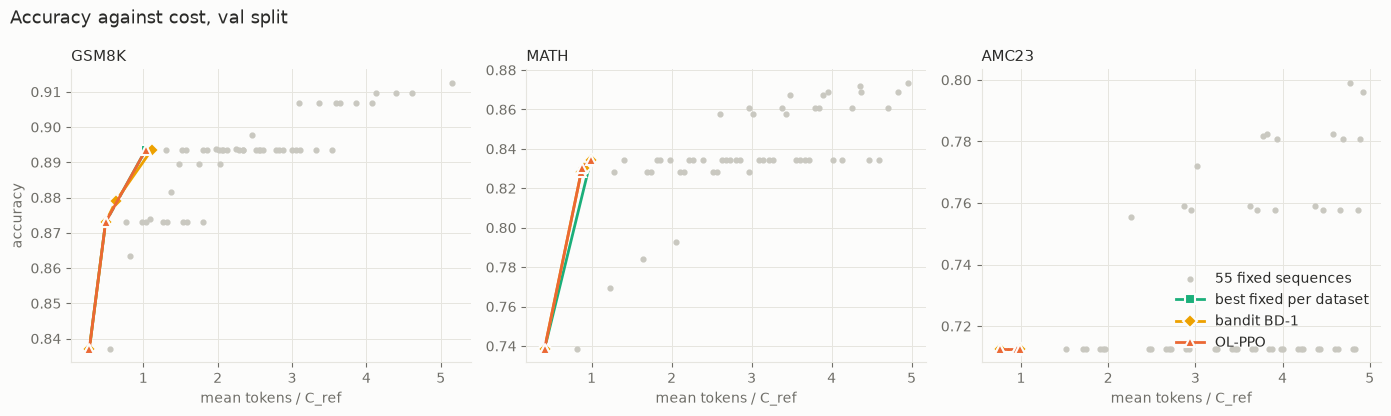

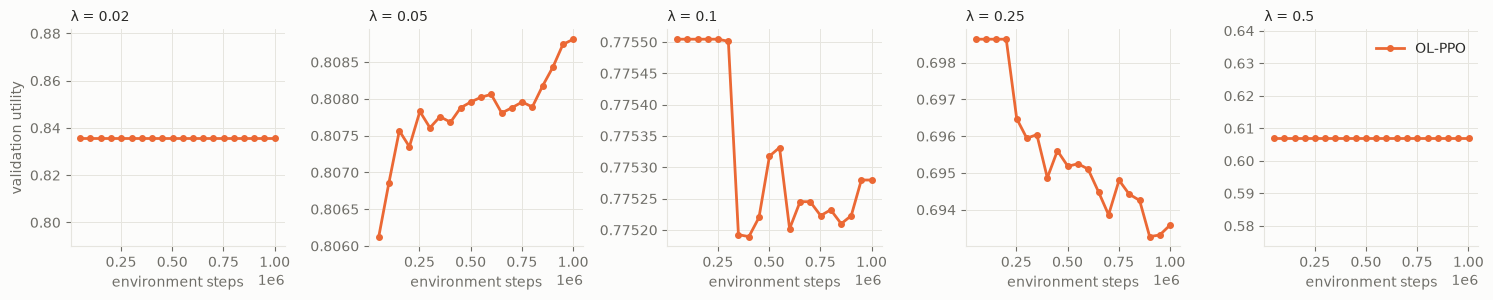

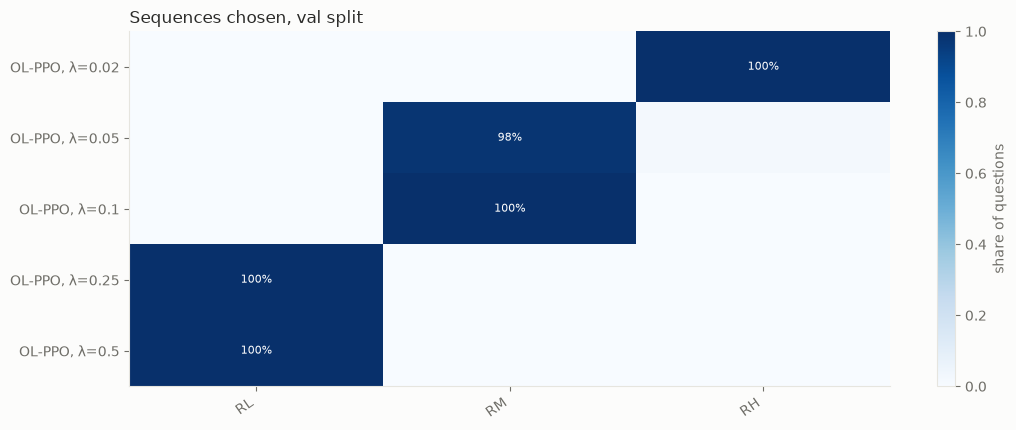

saved to /home/michel/Desktop/RL_experiments/rl_training/outputs/open_loop


In [15]:
INK, MUTED, GRID, SURFACE = "#2b2b29", "#6f6e68", "#e6e5df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": .7, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, d in zip(axes, DATASETS):
    part = results[results.dataset == d]
    fixed = part[part.method.str.startswith("fixed ")].drop_duplicates("method")
    ax.scatter(fixed.tokens / C_REF[d], fixed.accuracy, s=12, color="#c9c8c0", label="55 fixed sequences", zorder=2)
    for method, color, style in [("best fixed per dataset", AQUA, "s"), ("bandit BD-1", YELLOW, "D"), ("OL-PPO", ORANGE, "^")]:
        line = part[part.method == method].sort_values("tokens")
        if len(line):
            ax.plot(line.tokens / C_REF[d], line.accuracy, color=color, lw=2, marker=style, ms=7, mec=SURFACE, mew=1.5,
                    label=method, zorder=3)
    ax.set_title(d.upper(), loc="left", fontsize=11)
    ax.set_xlabel("mean tokens / C_ref")
axes[0].set_ylabel("accuracy")
axes[-1].legend(frameon=False, loc="lower right")
fig.suptitle(f"Accuracy against cost, {REPORT} split", x=.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES / f"{REPORT}_frontier.png", dpi=160)
plt.show()

curve_df = pd.DataFrame(curves)
fig, axes = plt.subplots(1, len(LAMBDAS), figsize=(15, 3.1), sharey=False)
for ax, lam in zip(axes, LAMBDAS):
    for method, color in (("OL-PPO", ORANGE),):
        part = curve_df[(curve_df.method == method) & (curve_df.lam == lam)]
        mean = part.groupby("steps").val_utility.mean()
        ax.plot(mean.index, mean.values, color=color, lw=2, marker="o", ms=4, label=method)
    ax.set_title(f"λ = {lam}", loc="left", fontsize=10)
    ax.set_xlabel("environment steps")
axes[0].set_ylabel("validation utility")
axes[-1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "learning_curves.png", dpi=160)
plt.show()

picked = np.concatenate([chosen[m, l] for m in TRAINERS for l in LAMBDAS])
top = [s for s, _ in sorted(enumerate(np.bincount(picked, minlength=55)), key=lambda x: -x[1]) if _ > 0][:12]
labels = [f"{m}, λ={l}" for m in TRAINERS for l in LAMBDAS]
freq = np.array([[(chosen[m, l] == s).mean() for s in top] for m in TRAINERS for l in LAMBDAS])
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.grid(False)
im = ax.imshow(freq, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(top)), [SEQ_NAMES[s] for s in top], rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
for a, b in zip(*np.where(freq >= .05)):
    ax.text(b, a, f"{freq[a, b]:.0%}", ha="center", va="center", color="white" if freq[a, b] > .55 else INK, fontsize=8)
fig.colorbar(im, ax=ax, label="share of questions")
ax.set_title(f"Sequences chosen, {REPORT} split", loc="left")
fig.tight_layout()
fig.savefig(FIGURES / f"{REPORT}_sequence_frequency.png", dpi=160)
plt.show()
print("saved to", OUT)

## Test results

The saved models were evaluated once on the test split. This cell only reads the saved results.

Test utility, all datasets


method,OL-PPO,bandit BD-1,best fixed per dataset,oracle
lam,,,,
0.02,0.8374,0.8364,0.8374,0.8837
0.05,0.8144,0.8112,0.8140,0.8560
0.10,0.7804,0.7804,0.7801,0.8201
0.25,0.7150,0.7150,0.7150,0.7400
0.50,0.6228,0.6228,0.6228,0.6333


Test accuracy, all datasets


method,OL-PPO,bandit BD-1,best fixed per dataset,oracle
lam,,,,
0.02,0.8567,0.8573,0.8567,0.9047
0.05,0.8478,0.8480,0.8496,0.8991
0.10,0.8469,0.8469,0.8507,0.8841
0.25,0.8071,0.8071,0.8071,0.8591
0.50,0.8071,0.8071,0.8071,0.8356


Per dataset


accuracy                                               tokens  \
method         OL-PPO bandit BD-1 best fixed per dataset oracle     OL-PPO   
dataset lam                                                                  
amc23   0.02    0.663       0.663                  0.663  0.794  16004.900   
        0.05    0.675       0.675                  0.663  0.774  15270.725   
        0.10    0.675       0.675                  0.675  0.727  15270.725   
        0.25    0.613       0.613                  0.613  0.675  10782.588   
        0.50    0.613       0.613                  0.613  0.675  10782.588   
gsm8k   0.02    0.910       0.910                  0.910  0.940   6382.890   
        0.05    0.897       0.897                  0.897  0.938   3190.745   
        0.10    0.897       0.897                  0.897  0.933   3190.745   
        0.25    0.867       0.867                  0.867  0.918   1827.248   
        0.50    0.867       0.867                  0.867  0.891   1827.248   
math    0.02    0.824       0.825                  0.824  0.878   8369.075   
        0.05    0.816       0.816                  0.824  0.871   7460.524   
        0.10    0.813       0.813                  0.824  0.849   7363.180   
        0.25    0.764       0.764                  0.764  0.816   3596.581   
        0.50    0.764       0.764                  0.764  0.791   3596.581   

                                                            
method       bandit BD-1 best fixed per dataset     oracle  
dataset lam                                                 
amc23   0.02   16004.900              16004.900  37739.750  
        0.05   15640.188              16004.900  27445.350  
        0.10   15270.725              15270.725  17759.238  
        0.25   10782.588              10782.588  11816.838  
        0.50   10782.588              10782.588  11816.838  
gsm8k   0.02    7005.377               6382.890   4224.261  
        0.05    3903.329               3190.745   3629.768  
        0.10    3190.745               3190.745   3170.491  
        0.25    1827.248               1827.248   2565.158  
        0.50    1827.248               1827.248   2007.135  
math    0.02    8990.885               8369.075  11006.719  
        0.05    7658.620               8369.075   9290.608  
        0.10    7363.180               8369.075   6398.099  
        0.25    3596.581               3596.581   4604.688  
        0.50    3596.581               3596.581   3945.800

Comparisons


,reference,method,lam,gain,ci_low,ci_high,p,p_holm
0,best fixed per dataset,OL-PPO,0.02,0.0000,0.0000,0.0000,1.0000,1.0000
1,best fixed per dataset,OL-PPO,0.05,0.0003,-0.0023,0.0034,0.8603,1.0000
2,best fixed per dataset,OL-PPO,0.10,0.0004,-0.0023,0.0028,0.7651,1.0000
3,best fixed per dataset,OL-PPO,0.25,0.0000,0.0000,0.0000,1.0000,1.0000
4,best fixed per dataset,OL-PPO,0.50,0.0000,0.0000,0.0000,1.0000,1.0000
5,bandit BD-1,OL-PPO,0.02,0.0010,-0.0003,0.0020,0.1072,0.4288
6,bandit BD-1,OL-PPO,0.05,0.0032,0.0006,0.0061,0.0138,0.0690
7,bandit BD-1,OL-PPO,0.10,0.0000,0.0000,0.0000,1.0000,1.0000
8,bandit BD-1,OL-PPO,0.25,0.0000,0.0000,0.0000,1.0000,1.0000
9,bandit BD-1,OL-PPO,0.50,0.0000,0.0000,0.0000,1.0000,1.0000


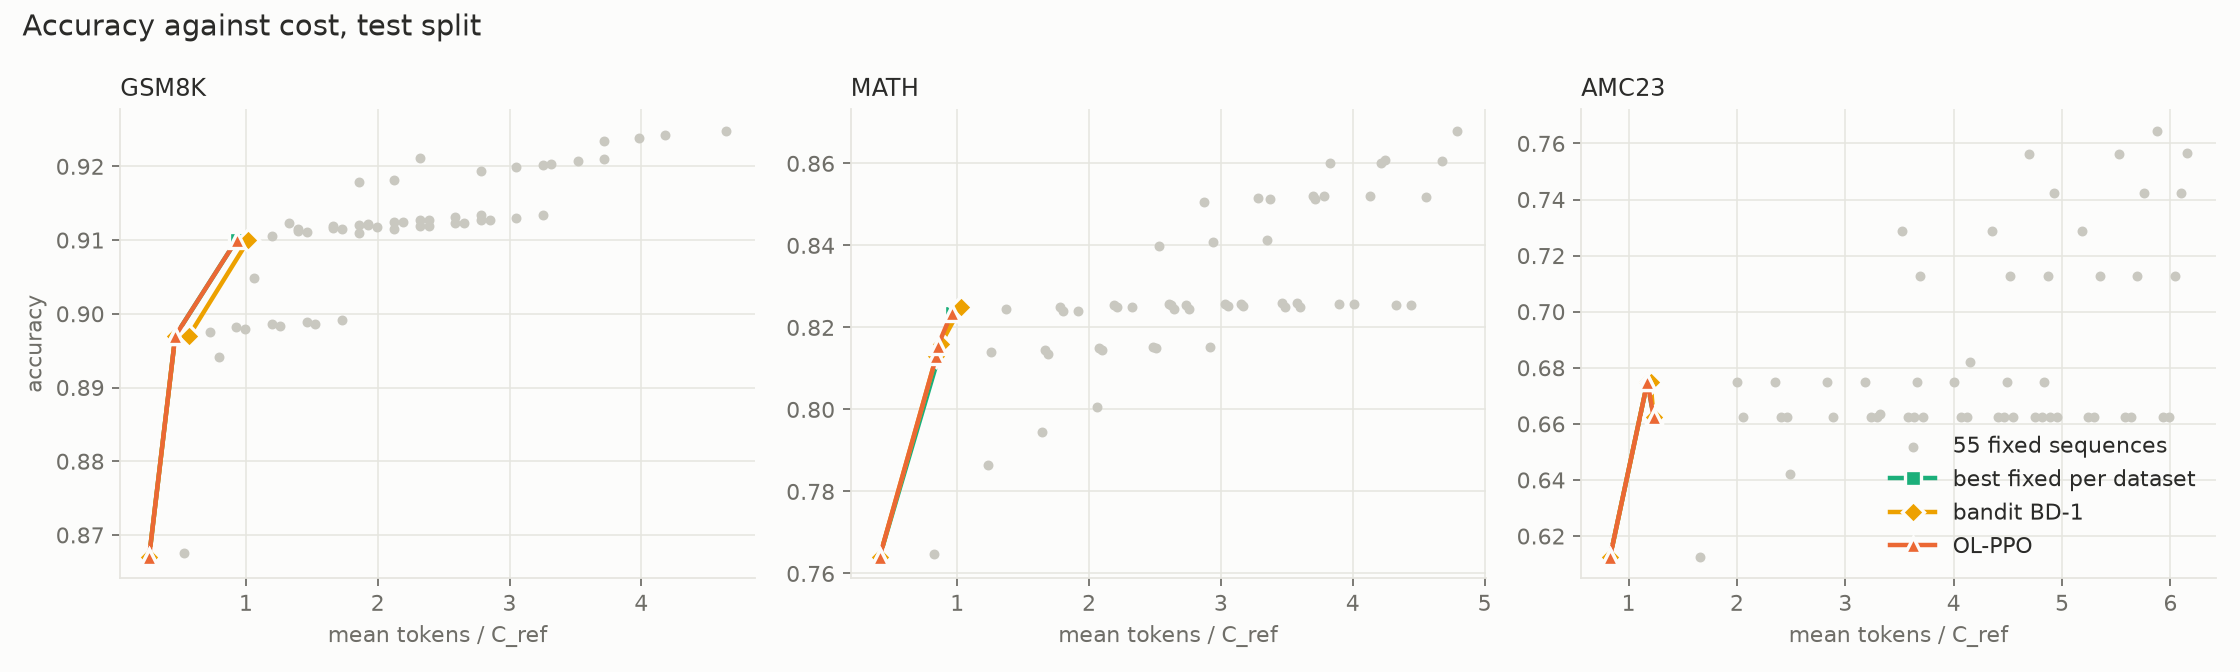

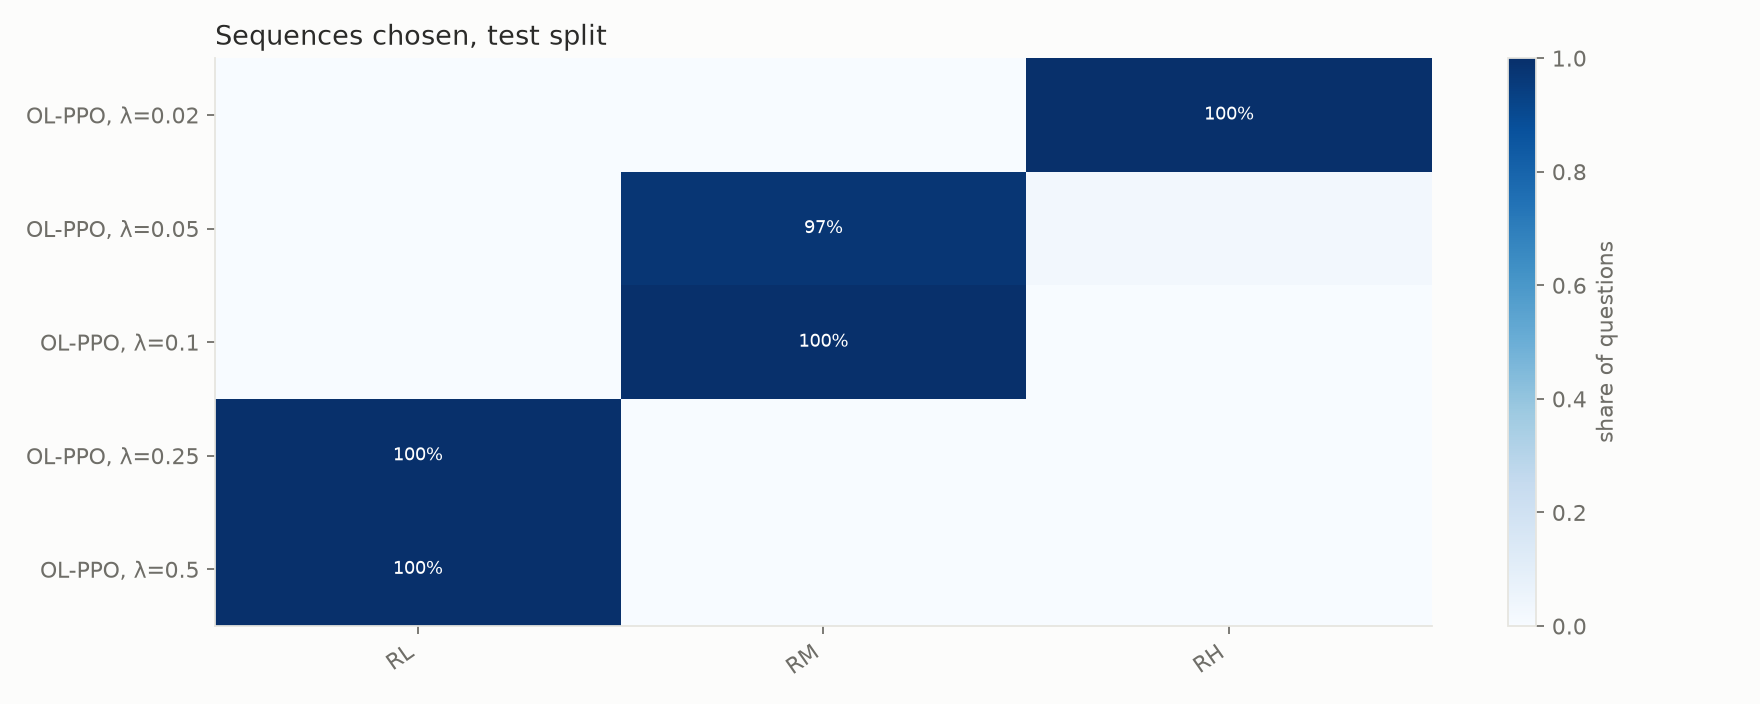

In [16]:
from IPython.display import Image, display
import pandas as pd
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "controller_data").is_dir())
OUT, FIG = ROOT / "rl_training/outputs/open_loop", ROOT / "figures/open_loop"
results = pd.read_csv(OUT / "test_metrics.csv")
main = ["OL-PPO", "bandit BD-1", "best fixed per dataset", "oracle"]
for value in ("utility", "accuracy"):
    print(f"Test {value}, all datasets")
    display(results[(results.dataset == "weighted") & results.method.isin(main)].pivot_table(index="lam", columns="method", values=value)[main].round(4))
print("Per dataset")
display(results[(results.dataset != "weighted") & results.method.isin(main)].pivot_table(index=["dataset", "lam"], columns="method", values=["accuracy", "tokens"]).round(3))
print("Comparisons")
display(pd.read_csv(OUT / "test_comparisons.csv").round(4))
for path in sorted(FIG.glob("test_*.png")):
    display(Image(filename=str(path), width=900))
